<a href="https://colab.research.google.com/github/VictorGMSS/Analisando_e_Prevendo_Series_Temporais/blob/main/Series_temporais_com_Prophet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importações do projeto

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from prophet import Prophet
import numpy as np
from sklearn.metrics import mean_squared_error
from prophet.plot import plot

# Aula 1 - Preparando e processando os dados

In [2]:
url = "https://raw.githubusercontent.com/VictorGMSS/Analisando_e_Prevendo_Series_Temporais/refs/heads/main/bicicletas.csv"

df = pd.read_csv(url)

df.head()

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,Nublado,Não,Sim,Inverno
1,2015-01-04 01:00:00,138,NaN,NaN,93.0,5.0,Céu limpo,Não,Sim,Inverno
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,Céu limpo,Não,Sim,Inverno
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,Céu limpo,Não,Sim,Inverno
4,2015-01-04 04:00:00,47,NaN,NaN,93.0,6.5,Céu limpo,Não,Sim,Inverno


### **ENTENDENDO AS COLUNAS**

**Dado numérico:**

*   `'contagem'`, `'temperatura'`, `'sensacao_termica'`, `'umidade'`, `'velocidade_vento'`, `'preco_base_envio'`.

**Categóricas:**

*   `'clima'`, `'feriado'`, `'fim_de_semana'`.

**Datas:**

*   `'data_hora'`.

**Alvo:**

*   `'estacao'`.

In [3]:
df.shape

(17429, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17429 entries, 0 to 17428
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   data_hora         17429 non-null  object 
 1   contagem          17429 non-null  int64  
 2   temperatura       17406 non-null  float64
 3   sensacao_termica  17406 non-null  float64
 4   umidade           17429 non-null  float64
 5   velocidade_vento  17429 non-null  float64
 6   clima             17429 non-null  object 
 7   feriado           17429 non-null  object 
 8   fim_de_semana     17429 non-null  object 
 9   estacao           17429 non-null  object 
dtypes: float64(4), int64(1), object(5)
memory usage: 1.3+ MB


In [5]:
#verificando dados nulos
df.isnull().sum()

,0
data_hora,0
contagem,0
temperatura,23
sensacao_termica,23
umidade,0
velocidade_vento,0
clima,0
feriado,0
fim_de_semana,0
estacao,0


In [6]:
#preenchendo dados usando a interpolação
df['temperatura'] = df['temperatura'].interpolate(method='linear')
df['sensacao_termica'] = df['sensacao_termica'].interpolate(method='linear')

In [7]:
#Conferindo os dados preenchidos
df.head(10)

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao
0,2015-01-04 00:00:00,182,3.00,2.00,93.0,6.0,Nublado,Não,Sim,Inverno
1,2015-01-04 01:00:00,138,2.75,2.25,93.0,5.0,Céu limpo,Não,Sim,Inverno
2,2015-01-04 02:00:00,134,2.50,2.50,96.5,0.0,Céu limpo,Não,Sim,Inverno
3,2015-01-04 03:00:00,72,2.00,2.00,100.0,0.0,Céu limpo,Não,Sim,Inverno
4,2015-01-04 04:00:00,47,2.00,2.00,93.0,6.5,Céu limpo,Não,Sim,Inverno
5,2015-01-04 05:00:00,46,2.00,2.00,93.0,4.0,Céu limpo,Não,Sim,Inverno
6,2015-01-04 06:00:00,51,1.00,-1.00,100.0,7.0,Parcialmente nublado,Não,Sim,Inverno
7,2015-01-04 07:00:00,75,1.00,-1.00,100.0,7.0,Parcialmente nublado,Não,Sim,Inverno
8,2015-01-04 08:00:00,131,1.50,-1.00,96.5,8.0,Parcialmente nublado,Não,Sim,Inverno
9,2015-01-04 09:00:00,301,2.00,-0.50,100.0,9.0,Nublado,Não,Sim,Inverno


In [8]:
#Quantos dados duplicados nos temos?
df.duplicated().sum()

np.int64(15)

In [9]:
duplicatas = df.duplicated(keep=False)

linhas_duplicadas = df[duplicatas]

linhas_duplicadas.sort_values(by='data_hora')

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao
519,2015-01-25 16:00:00,1238,8.0,5.0,71.0,18.0,Nublado,Não,Sim,Inverno
17422,2015-01-25 16:00:00,1238,8.0,5.0,71.0,18.0,Nublado,Não,Sim,Inverno
869,2015-02-09 06:00:00,479,5.0,3.5,87.0,6.5,Parcialmente nublado,Não,Não,Inverno
17417,2015-02-09 06:00:00,479,5.0,3.5,87.0,6.5,Parcialmente nublado,Não,Não,Inverno
3655,2015-06-05 18:00:00,3411,23.0,23.0,50.0,26.0,Parcialmente nublado,Não,Não,Verão
17425,2015-06-05 18:00:00,3411,23.0,23.0,50.0,26.0,Parcialmente nublado,Não,Não,Verão
4167,2015-06-27 02:00:00,337,15.5,15.5,74.5,18.0,Parcialmente nublado,Não,Sim,Verão
17421,2015-06-27 02:00:00,337,15.5,15.5,74.5,18.0,Parcialmente nublado,Não,Sim,Verão
4658,2015-07-17 14:00:00,1882,24.5,24.5,44.0,29.5,Parcialmente nublado,Não,Não,Verão
17418,2015-07-17 14:00:00,1882,24.5,24.5,44.0,29.5,Parcialmente nublado,Não,Não,Verão


In [10]:
df_limpo = df.drop_duplicates()

In [11]:
df_limpo.shape

(17414, 10)

# Aula 2 - Explorando os dados numericos

In [12]:
df_limpo.describe()

,contagem,temperatura,sensacao_termica,umidade,velocidade_vento
count,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000
mean,1143.101642,12.468206,11.521080,72.324954,15.913063
std,1085.108068,5.571670,6.614799,14.313186,7.894570
min,0.000000,-1.500000,-6.000000,20.500000,0.000000
25%,257.000000,8.000000,6.000000,63.000000,10.000000
50%,844.000000,12.500000,12.500000,74.500000,15.000000
75%,1671.750000,16.000000,16.000000,83.000000,20.500000
max,7860.000000,34.000000,34.000000,100.000000,56.500000


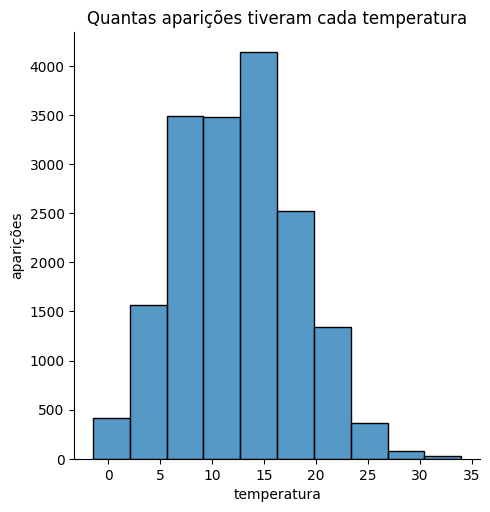

In [13]:
ax = sns.displot(df_limpo, x='temperatura', bins=10)
ax.set(title = "Quantas aparições tiveram cada temperatura", xlabel="temperatura", ylabel="aparições")

plt.show()

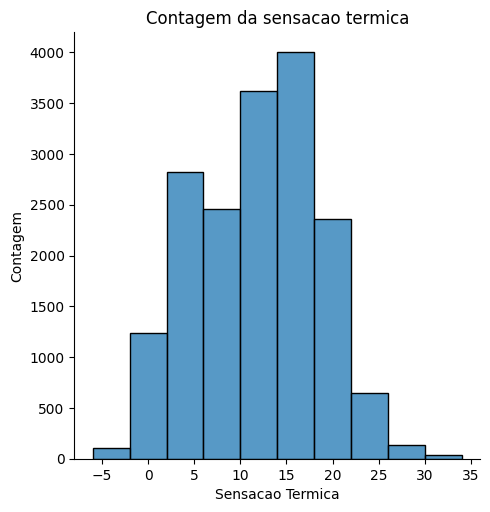

In [14]:
ax = sns.displot(df_limpo, x='sensacao_termica', bins=10)
ax.set(title = "Contagem da sensacao termica", xlabel="Sensacao Termica", ylabel="Contagem")

plt.show()

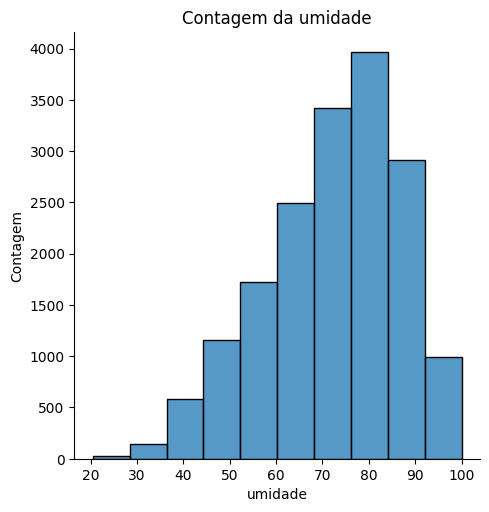

In [15]:
ax = sns.displot(df_limpo, x='umidade', bins=10)
ax.set(title = "Contagem da umidade", xlabel="umidade", ylabel="Contagem")

plt.show()

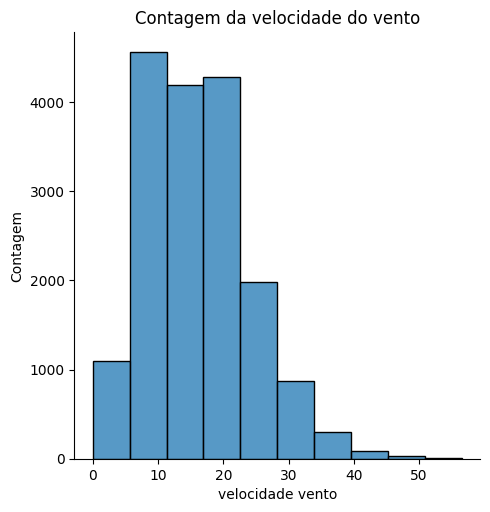

In [16]:
ax = sns.displot(df_limpo, x='velocidade_vento', bins=10)
ax.set(title = "Contagem da velocidade do vento", xlabel="velocidade vento", ylabel="Contagem")

plt.show()

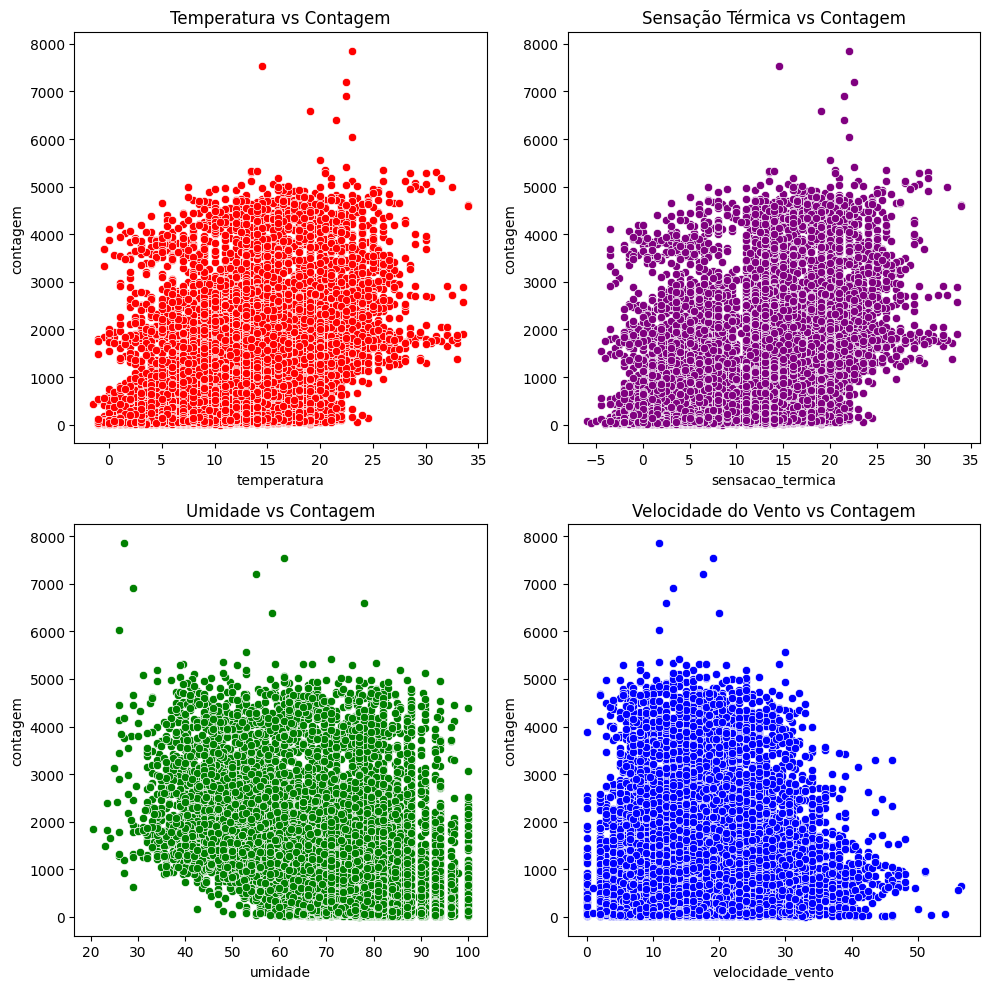

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

sns.scatterplot(data=df_limpo, x='temperatura', y='contagem', ax=axes[0, 0], color='red')
axes[0, 0].set_title('Temperatura vs Contagem')

sns.scatterplot(data=df_limpo, x='sensacao_termica', y='contagem', ax=axes[0, 1], color='purple')
axes[0, 1].set_title('Sensação Térmica vs Contagem')

sns.scatterplot(data=df_limpo, x='umidade', y='contagem', ax=axes[1, 0], color='green')
axes[1, 0].set_title('Umidade vs Contagem')

sns.scatterplot(data=df_limpo, x='velocidade_vento', y='contagem', ax=axes[1, 1], color='blue')
axes[1, 1].set_title('Velocidade do Vento vs Contagem')

plt.tight_layout()
plt.show()

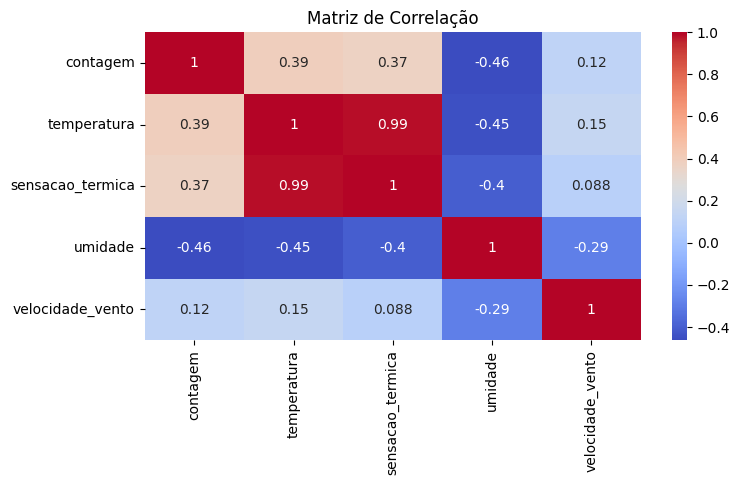

In [18]:
#Mapa de calor da correlação entre as variaveis numericas
plt.figure(figsize=(8, 4))

sns.heatmap(df_limpo.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação')

plt.show()

# Aula 3: Explorando os dados categoricos

In [19]:
df_limpo.describe(include=[object])

,data_hora,clima,feriado,fim_de_semana,estacao
count,17414,17414,17414,17414,17414
unique,17414,6,2,2,4
top,2017-01-03 23:00:00,Céu limpo,Não,Não,Primavera
freq,1,6150,17030,12444,4394


In [20]:
for col in ['clima',	'feriado',	'fim_de_semana',	'estacao']:
  print(f'Coluna: {col}')
  print(df_limpo[col].unique())
  print('='*80, '\n')

Coluna: clima
['Nublado' 'Céu limpo' 'Parcialmente nublado' 'Chuva leve' 'Neve'
 'Chuva com trovoadas']

Coluna: feriado
['Não' 'Sim']

Coluna: fim_de_semana
['Sim' 'Não']

Coluna: estacao
['Inverno' 'Primavera' 'Verão' 'Outono']



## Analisando relação Feriado (Sim, Não) X alugueis



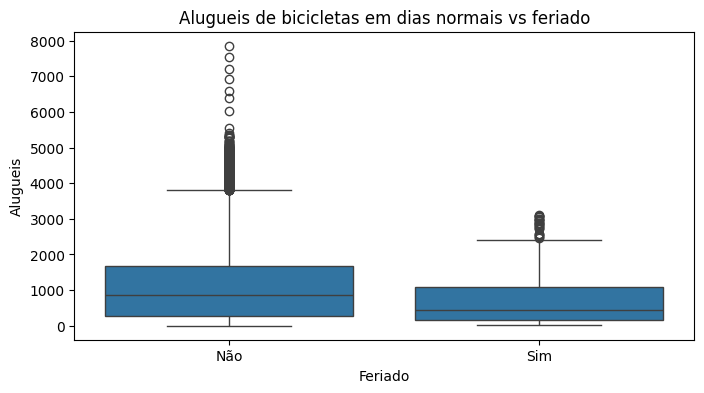

In [21]:
plt.figure(figsize=(8,4))
sns.boxplot(x='feriado', y='contagem', data=df_limpo)
plt.title('Alugueis de bicicletas em dias normais vs feriado')
plt.xlabel('Feriado')
plt.ylabel('Alugueis')
plt.show()

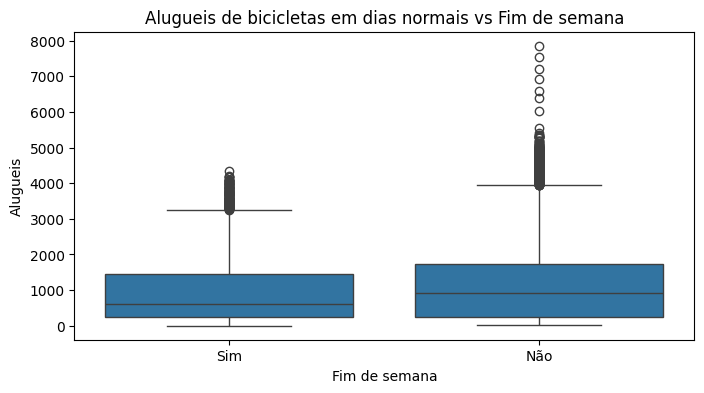

In [22]:
plt.figure(figsize=(8,4))
sns.boxplot(x='fim_de_semana', y='contagem', data=df_limpo)
plt.title('Alugueis de bicicletas em dias normais vs Fim de semana')
plt.xlabel('Fim de semana')
plt.ylabel('Alugueis')
plt.show()

In [23]:
mediana_feriado = df_limpo.groupby('feriado')['contagem'].median()
mediana_fim_de_semana = df_limpo.groupby('fim_de_semana')['contagem'].median()

print(mediana_feriado, '\n\n', mediana_fim_de_semana)

feriado
Não    855.0
Sim    439.5
Name: contagem, dtype: float64 

 fim_de_semana
Não    927.0
Sim    619.0
Name: contagem, dtype: float64


## Analisando clima X alugueis das bicicletas


*   Nublado
*   Céu limpo
*   Nublado
*   Parcialmente nublado
*   Chuva leve
*   Neve
*   Chuva com trovoadas


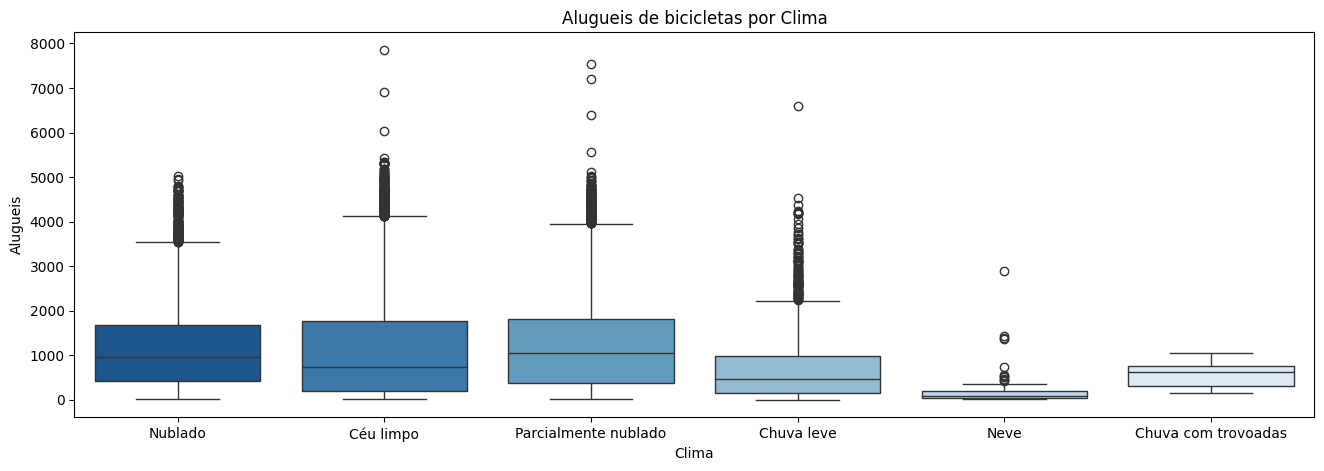

In [24]:
plt.figure(figsize=(16,5))
sns.boxplot(x='clima', y='contagem', data=df_limpo, hue='clima', palette='Blues_r')
plt.title('Alugueis de bicicletas por Clima')
plt.xlabel('Clima')
plt.ylabel('Alugueis')
plt.show()

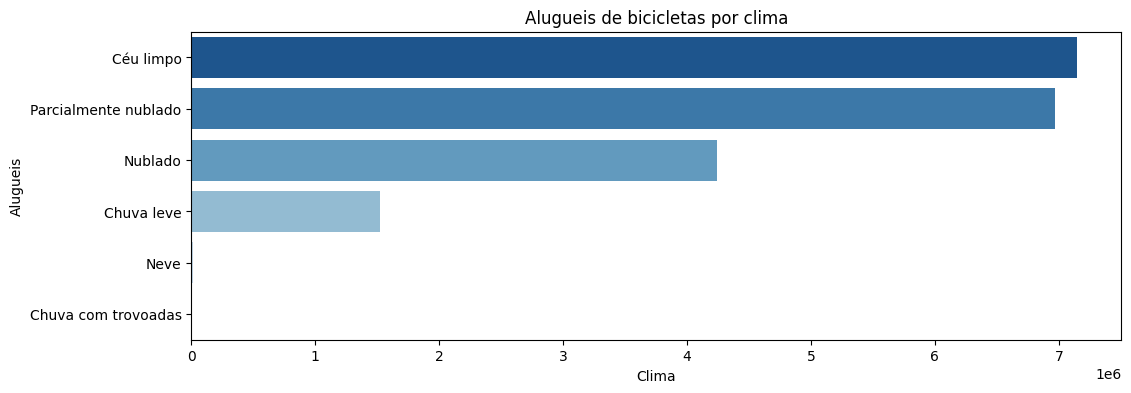

In [25]:
df_clima = df_limpo.groupby('clima')['contagem'].sum().reset_index().sort_values(by='contagem', ascending=False)

plt.figure(figsize=(12,4))
sns.barplot(y='clima', x='contagem', data=df_clima, hue='clima', palette='Blues_r', orient='h')
plt.title('Alugueis de bicicletas por clima')
plt.xlabel('Clima')
plt.ylabel('Alugueis')

plt.show()

In [26]:
df_limpo.groupby('clima')['contagem'].median().sort_values(ascending=False)

,contagem
clima,
Parcialmente nublado,1050.5
Nublado,964.0
Céu limpo,745.0
Chuva com trovoadas,620.5
Chuva leve,471.0
Neve,88.0


## Analisando estações X alugueis das bicicletas


*   Verão
*   Outono
*   Primavera
*   Inverno

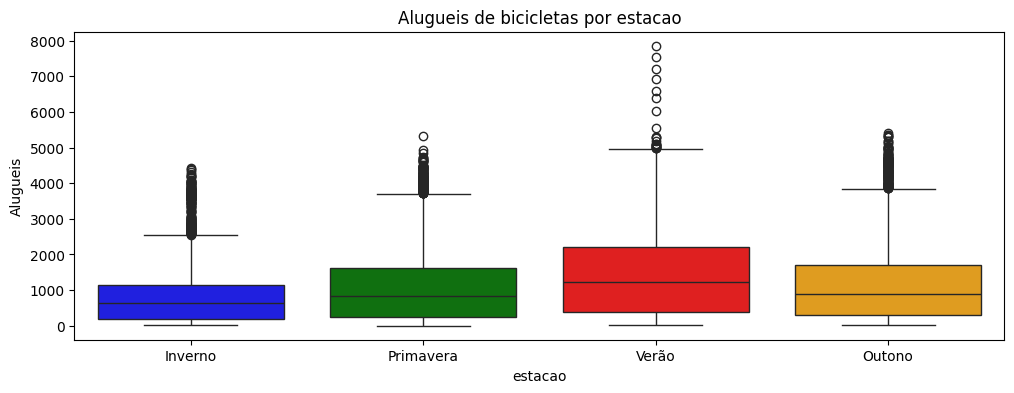

In [27]:
plt.figure(figsize=(12,4))
paleta_cores = {'Verão': 'red', 'Outono': 'orange', 'Primavera': 'green', 'Inverno': 'blue'}
sns.boxplot(x='estacao', y='contagem', data=df_limpo, hue='estacao', palette=paleta_cores)
plt.title('Alugueis de bicicletas por estacao')
plt.xlabel('estacao')
plt.ylabel('Alugueis')
plt.show()

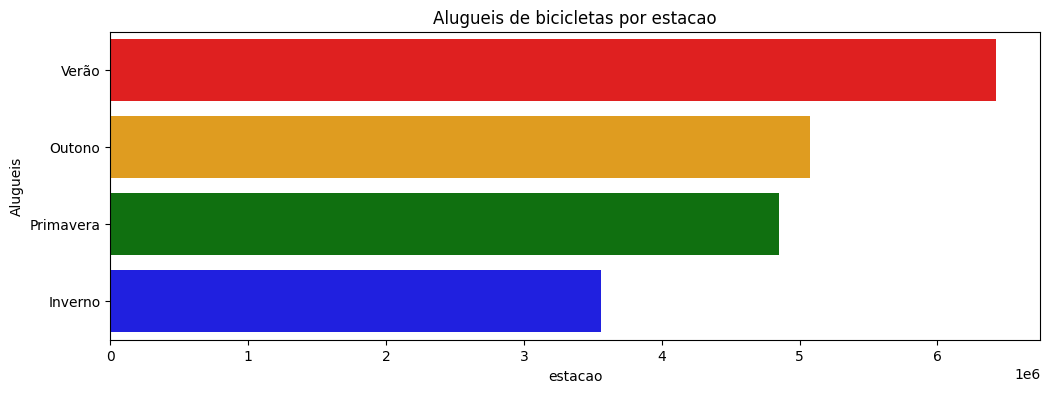

In [28]:
df_estacao = df_limpo.groupby('estacao')['contagem'].sum().reset_index().sort_values(by='contagem', ascending=False)

plt.figure(figsize=(12,4))
sns.barplot(y='estacao', x='contagem', data=df_estacao, hue='estacao', palette=paleta_cores, orient='h')
plt.title('Alugueis de bicicletas por estacao')
plt.xlabel('estacao')
plt.ylabel('Alugueis')

plt.show()

In [29]:
df_limpo.groupby('estacao')['contagem'].median().sort_values(ascending=False)

,contagem
estacao,
Verão,1214.0
Outono,898.0
Primavera,823.0
Inverno,632.0


In [30]:
primavera = df_limpo[df_limpo['estacao'] == 'Primavera']['contagem']
outono = df_limpo[df_limpo['estacao'] == 'Outono']['contagem']

u_statistic, p_value = mannwhitneyu(primavera, outono, alternative='two-sided')

print(f"u-statistic: {u_statistic}")
print(f"p-value: {p_value}")

u-statistic: 9044682.5
p-value: 0.0004762100221646296


# Aula 4: Analisando os dados ao longo do tempo

In [31]:
df_limpo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   data_hora         17414 non-null  object 
 1   contagem          17414 non-null  int64  
 2   temperatura       17414 non-null  float64
 3   sensacao_termica  17414 non-null  float64
 4   umidade           17414 non-null  float64
 5   velocidade_vento  17414 non-null  float64
 6   clima             17414 non-null  object 
 7   feriado           17414 non-null  object 
 8   fim_de_semana     17414 non-null  object 
 9   estacao           17414 non-null  object 
dtypes: float64(4), int64(1), object(5)
memory usage: 1.5+ MB


In [32]:
df_data = df_limpo.copy()

In [33]:
df_data['data_hora'] = pd.to_datetime(df_data['data_hora'])

df_data.head()

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao
0,2015-01-04 00:00:00,182,3.00,2.00,93.0,6.0,Nublado,Não,Sim,Inverno
1,2015-01-04 01:00:00,138,2.75,2.25,93.0,5.0,Céu limpo,Não,Sim,Inverno
2,2015-01-04 02:00:00,134,2.50,2.50,96.5,0.0,Céu limpo,Não,Sim,Inverno
3,2015-01-04 03:00:00,72,2.00,2.00,100.0,0.0,Céu limpo,Não,Sim,Inverno
4,2015-01-04 04:00:00,47,2.00,2.00,93.0,6.5,Céu limpo,Não,Sim,Inverno


In [34]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   data_hora         17414 non-null  datetime64[ns]
 1   contagem          17414 non-null  int64         
 2   temperatura       17414 non-null  float64       
 3   sensacao_termica  17414 non-null  float64       
 4   umidade           17414 non-null  float64       
 5   velocidade_vento  17414 non-null  float64       
 6   clima             17414 non-null  object        
 7   feriado           17414 non-null  object        
 8   fim_de_semana     17414 non-null  object        
 9   estacao           17414 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(4)
memory usage: 1.5+ MB


In [35]:
df_data['mes'] = df_data['data_hora'].dt.month
df_data['horario'] = df_data['data_hora'].dt.hour
df_data['data_hora'] = df_data['data_hora'].dt.date

In [36]:
df_data.head()

,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao,mes,horario
0,2015-01-04,182,3.00,2.00,93.0,6.0,Nublado,Não,Sim,Inverno,1,0
1,2015-01-04,138,2.75,2.25,93.0,5.0,Céu limpo,Não,Sim,Inverno,1,1
2,2015-01-04,134,2.50,2.50,96.5,0.0,Céu limpo,Não,Sim,Inverno,1,2
3,2015-01-04,72,2.00,2.00,100.0,0.0,Céu limpo,Não,Sim,Inverno,1,3
4,2015-01-04,47,2.00,2.00,93.0,6.5,Céu limpo,Não,Sim,Inverno,1,4


In [37]:
df_data = df_data.rename(columns={'data_hora': 'data'})

In [38]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17414 entries, 0 to 17413
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   data              17414 non-null  object 
 1   contagem          17414 non-null  int64  
 2   temperatura       17414 non-null  float64
 3   sensacao_termica  17414 non-null  float64
 4   umidade           17414 non-null  float64
 5   velocidade_vento  17414 non-null  float64
 6   clima             17414 non-null  object 
 7   feriado           17414 non-null  object 
 8   fim_de_semana     17414 non-null  object 
 9   estacao           17414 non-null  object 
 10  mes               17414 non-null  int32  
 11  horario           17414 non-null  int32  
dtypes: float64(4), int32(2), int64(1), object(5)
memory usage: 2.1+ MB


In [39]:
df_data['data'] = pd.to_datetime(df_data['data'])

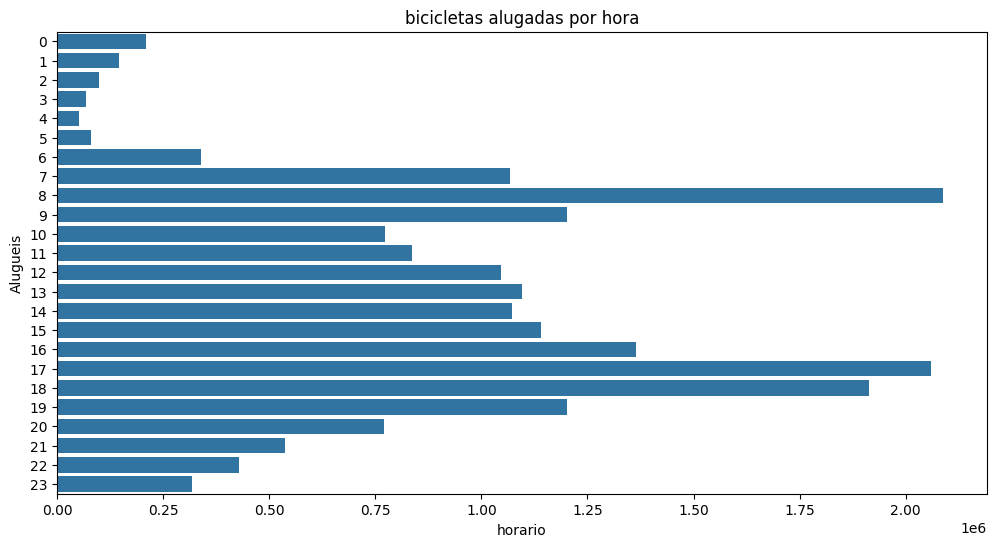

In [40]:
df_por_hora = df_data.groupby('horario')['contagem'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.barplot(y='horario', x='contagem', data=df_por_hora, orient='h')
plt.title('bicicletas alugadas por hora')
plt.xlabel('horario')
plt.ylabel('Alugueis')

plt.show()

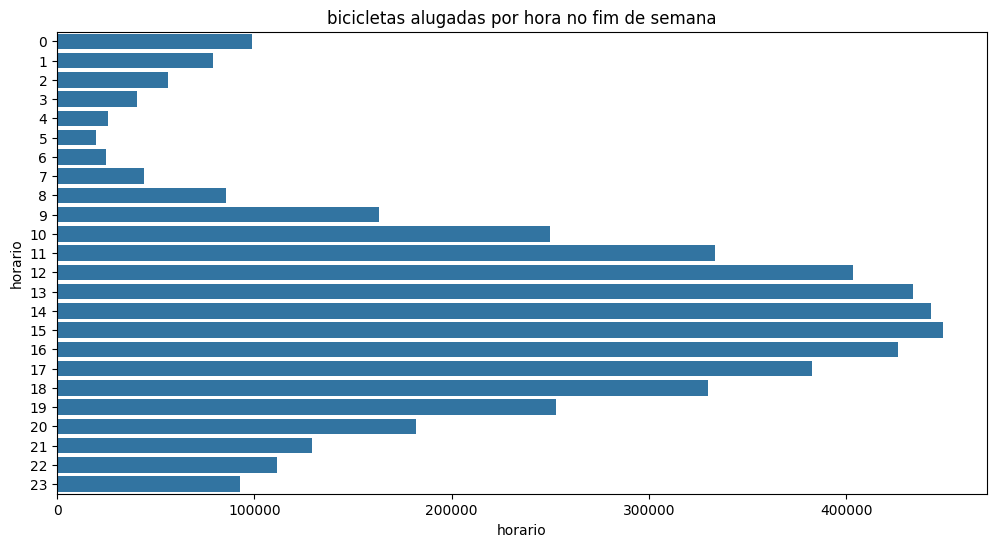

In [41]:
df_fim_de_semana = df_data[df_data['fim_de_semana'] == 'Sim']
alugueis_fim_de_semana = df_fim_de_semana.groupby('horario')['contagem'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.barplot(y='horario', x='contagem', data=alugueis_fim_de_semana, orient='h')
plt.title('bicicletas alugadas por hora no fim de semana')
plt.xlabel('horario')
plt.show()

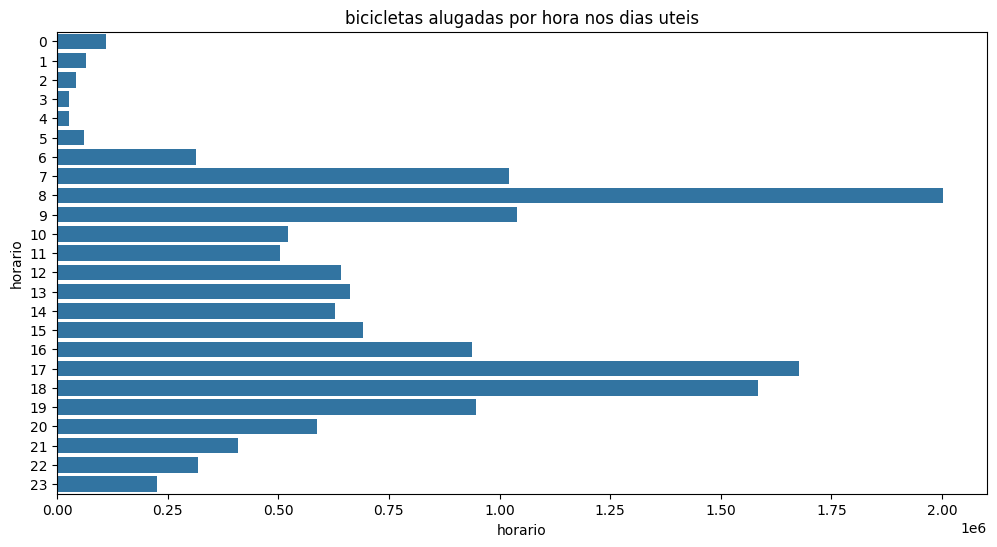

In [42]:
df_dias_de_semana = df_data[df_data['fim_de_semana'] == 'Não']
alugueis_dias_de_semana = df_dias_de_semana.groupby('horario')['contagem'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.barplot(y='horario', x='contagem', data=alugueis_dias_de_semana, orient='h')
plt.title('bicicletas alugadas por hora nos dias uteis')
plt.xlabel('horario')
plt.show()

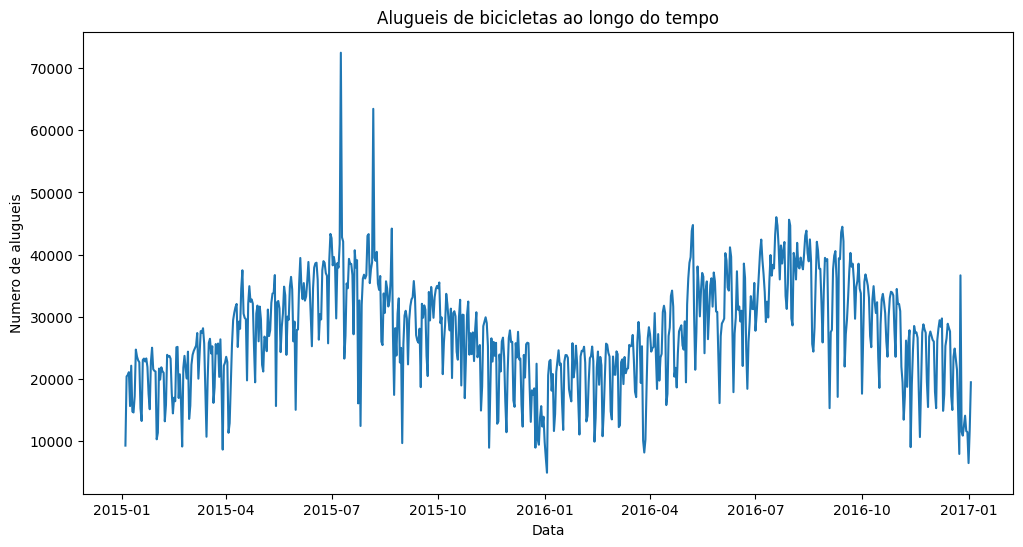

In [43]:
df_tempo = df_data.groupby('data')['contagem'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.lineplot(data=df_tempo, x='data', y='contagem')
plt.title('Alugueis de bicicletas ao longo do tempo')
plt.xlabel('Data')
plt.ylabel('Numero de alugueis')
plt.show()

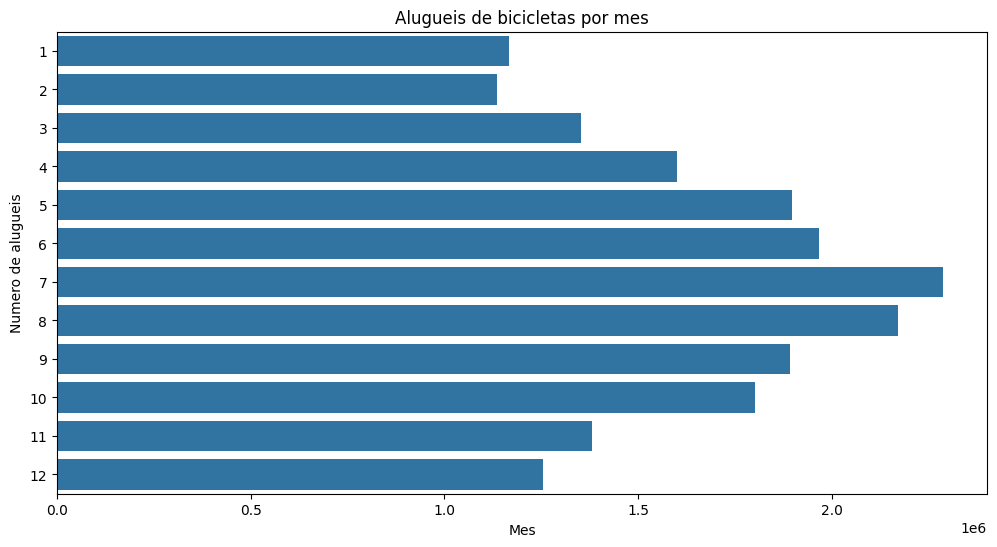

In [44]:
alugueis_mensais = df_data.groupby('mes')['contagem'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.barplot(data=alugueis_mensais, y='mes', x='contagem', orient='h')
plt.title('Alugueis de bicicletas por mes')
plt.xlabel('Mes')
plt.ylabel('Numero de alugueis')
plt.show()


# Aula 5: Construindo o modelo preditivo

In [45]:
df_prophet = df_data[['data', 'contagem']].rename(columns={'data': 'ds', 'contagem': 'y'})

df_prophet.head()

,ds,y
0,2015-01-04,182
1,2015-01-04,138
2,2015-01-04,134
3,2015-01-04,72
4,2015-01-04,47


In [46]:
df_prophet = df_prophet.groupby('ds')['y'].sum().reset_index()

df_prophet

,ds,y
0,2015-01-04,9234
1,2015-01-05,20372
2,2015-01-06,20613
3,2015-01-07,21064
4,2015-01-08,15601
...,...,...
725,2016-12-30,11566
726,2016-12-31,11424
727,2017-01-01,6421
728,2017-01-02,11823


In [47]:
np.random.seed(4587)

modelo = Prophet(daily_seasonality=True)

modelo.fit(df_prophet)
futuro = modelo.make_future_dataframe(periods=90, freq='D')
previsao = modelo.predict(futuro)

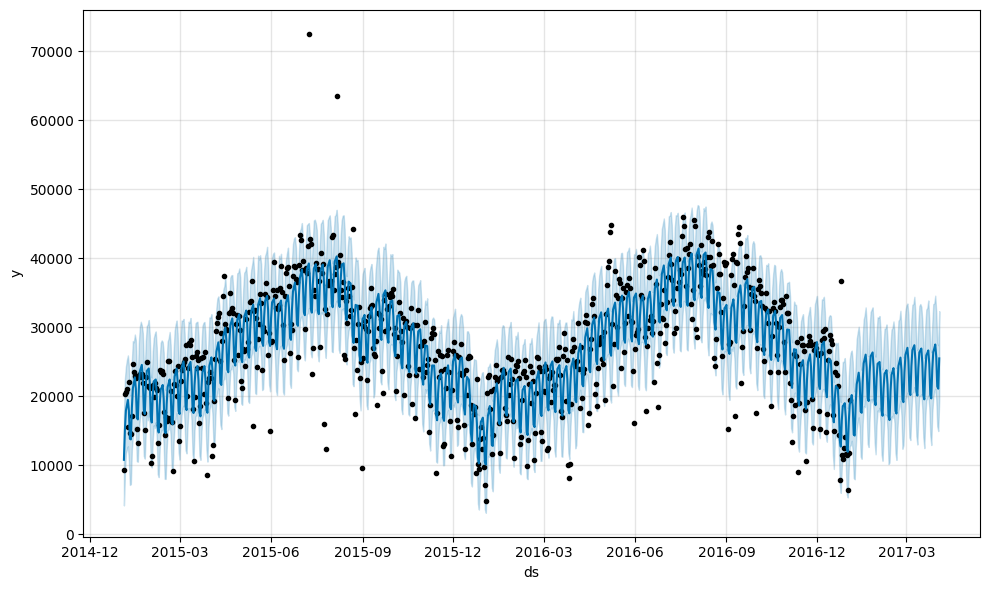

In [48]:
fig1 = modelo.plot(previsao)

In [49]:
previsao[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

,ds,yhat,yhat_lower,yhat_upper
0,2015-01-04,10779.107530,4167.618214,17026.711614
1,2015-01-05,15196.499062,8814.641564,22503.429160
2,2015-01-06,17906.863863,11738.006490,24290.621913
3,2015-01-07,18644.470699,12260.000002,25247.989586
4,2015-01-08,19463.055407,12733.639821,25914.240382
...,...,...,...,...
815,2017-03-30,27489.955288,21084.733825,34570.330754
816,2017-03-31,25717.883876,19548.792420,32210.122452
817,2017-04-01,21400.600291,15642.395294,27875.734209
818,2017-04-02,21086.892052,14946.272588,27391.459780


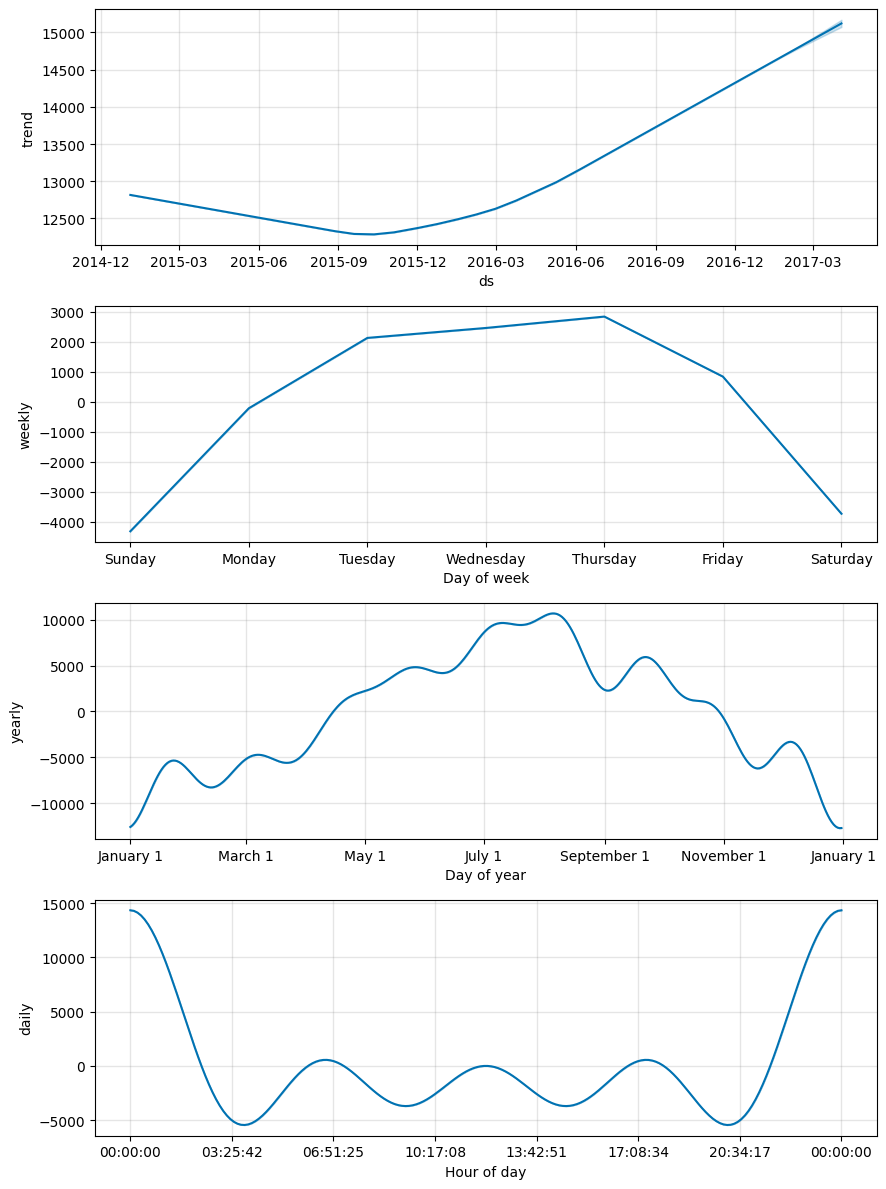

In [50]:
fig2 = modelo.plot_components(previsao)

In [51]:
df_prophet.shape

(730, 2)

In [52]:
df_treino = pd.DataFrame()

df_treino['ds'] = df_prophet['ds'][:584]
df_treino['y'] = df_prophet['y'][:584]

In [53]:
df_teste = pd.DataFrame()

df_teste['ds'] = df_prophet['ds'][584:]
df_teste['y'] = df_prophet['y'][584:]

In [54]:
np.random.seed(4587)

modelo = Prophet()
modelo.fit(df_treino)
futuro = modelo.make_future_dataframe(periods=150, freq='D')
previsao = modelo.predict(futuro)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


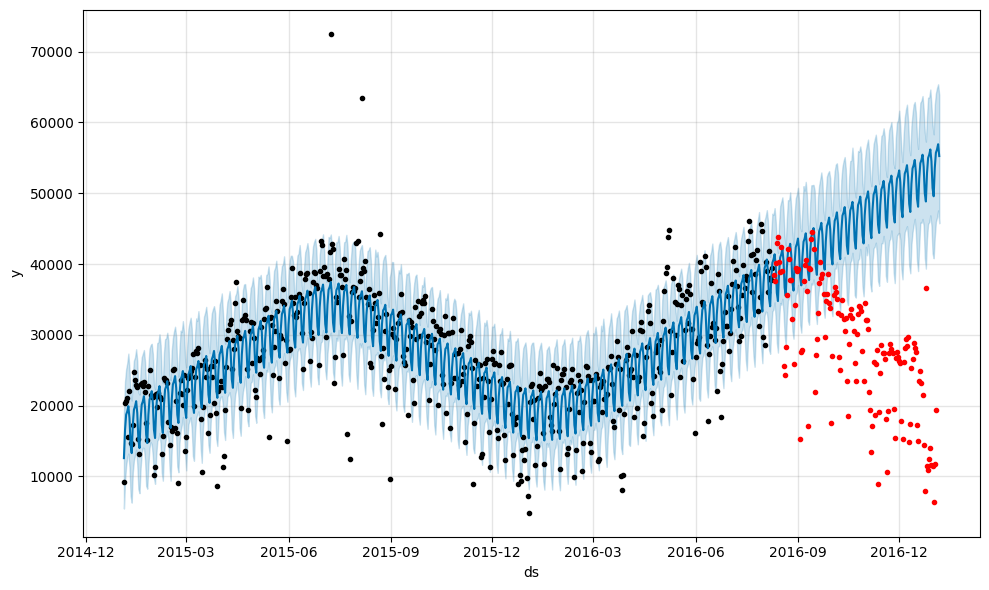

In [55]:
fig1 = modelo.plot(previsao)

plt.plot(df_teste['ds'], df_teste['y'], '.r')

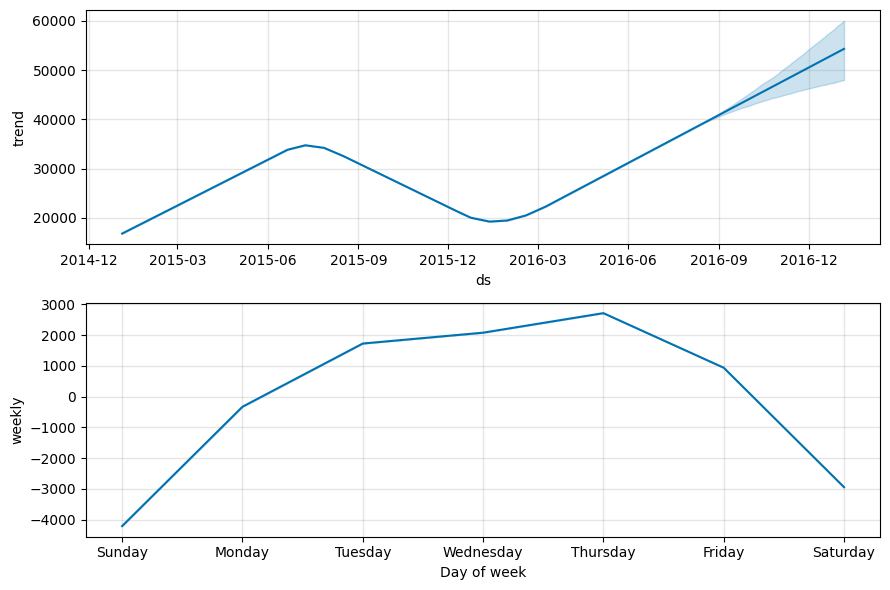

In [56]:
fig2 = modelo.plot_components(previsao)

In [57]:
df_previsao = previsao[['ds', 'yhat']]
df_comparacao = pd.merge(df_previsao, df_teste, on='ds')
df_comparacao

,ds,yhat,y
0,2016-08-10,40638.924004,38430
1,2016-08-11,41379.878413,37626
2,2016-08-12,39710.908894,40159
3,2016-08-13,35931.531686,43041
4,2016-08-14,34772.410968,43848
...,...,...,...
141,2016-12-30,54515.628885,11566
142,2016-12-31,50736.251677,11424
143,2017-01-01,49577.130958,6421
144,2017-01-02,53563.143544,11823


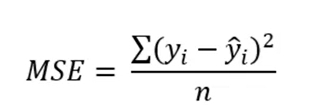

In [58]:
mse = mean_squared_error(df_comparacao['y'], df_comparacao['yhat'])
rmse = np.sqrt(mse)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')

MSE: 466327101.5154366
RMSE: 21594.60815841391


# Aula 6: Melhorando as previsões

In [59]:
np.random.seed(4587)

modelo = Prophet(yearly_seasonality=True)

modelo.fit(df_treino)
futuro = modelo.make_future_dataframe(periods=150, freq='D')
previsao = modelo.predict(futuro)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


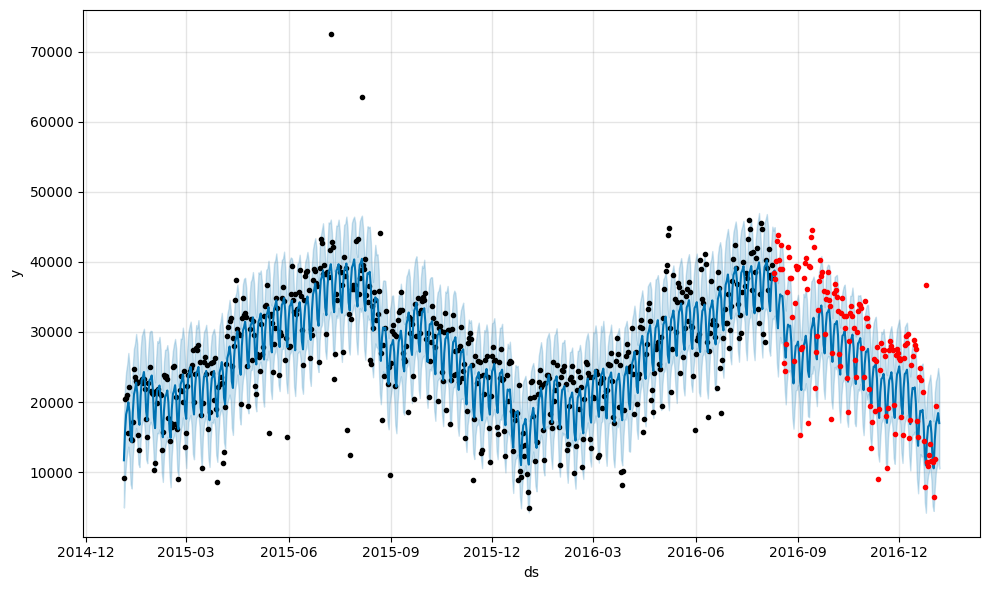

In [60]:
fig1 = modelo.plot(previsao)

plt.plot(df_teste['ds'], df_teste['y'], '.r');

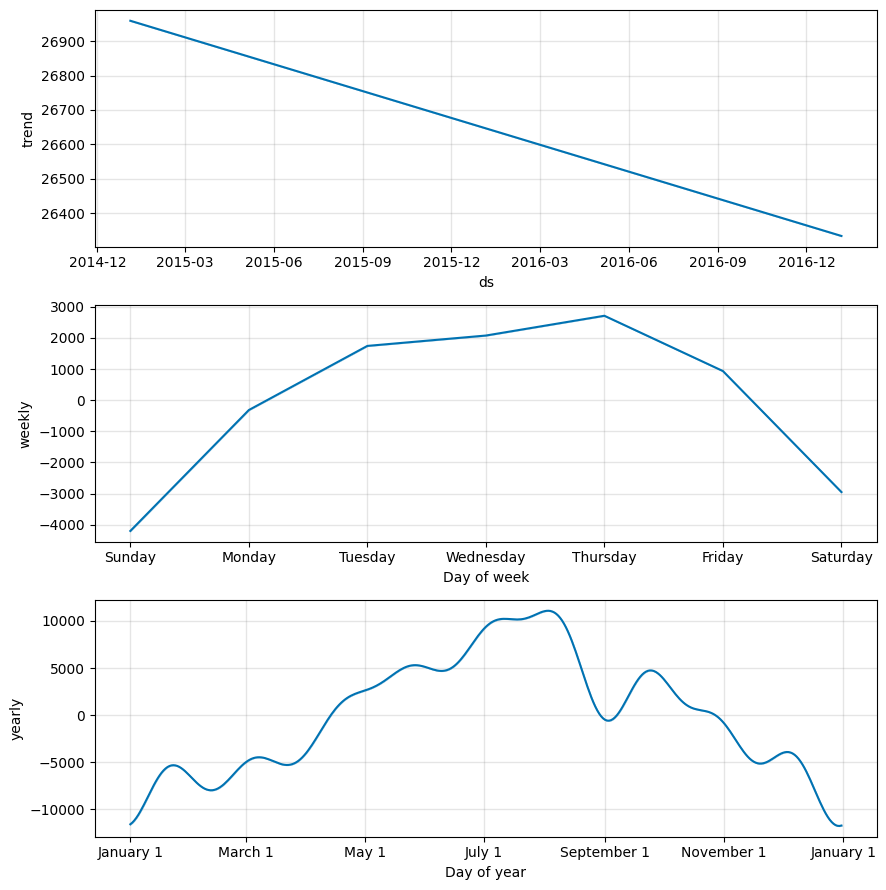

In [61]:
fig2 = modelo.plot_components(previsao)

In [62]:
df_previsao = previsao[['ds', 'yhat']]
df_comparacao = pd.merge(df_teste, df_previsao, on='ds')
df_comparacao

,ds,y,yhat
0,2016-08-10,38430,38490.372885
1,2016-08-11,37626,38773.554293
2,2016-08-12,40159,36598.124990
3,2016-08-13,43041,32265.950752
4,2016-08-14,43848,30524.954631
...,...,...,...
141,2016-12-30,11566,15518.966341
142,2016-12-31,11424,11691.708228
143,2017-01-01,6421,10556.751273
144,2017-01-02,11823,14609.167879


In [63]:
mse = mean_squared_error(df_comparacao['y'], df_comparacao['yhat'])
rmse = np.sqrt(mse)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')

MSE: 38326592.525717966
RMSE: 6190.847480411544


In [64]:
df_prophet

,ds,y
0,2015-01-04,9234
1,2015-01-05,20372
2,2015-01-06,20613
3,2015-01-07,21064
4,2015-01-08,15601
...,...,...
725,2016-12-30,11566
726,2016-12-31,11424
727,2017-01-01,6421
728,2017-01-02,11823


In [65]:
np.random.seed(4587)

modelo = Prophet()
modelo.fit(df_prophet)
futuro = modelo.make_future_dataframe(periods=0)
previsao = modelo.predict(futuro)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [66]:
sem_outiliers = df_prophet[(df_prophet['y'] > previsao['yhat_lower']) & (df_prophet['y'] < previsao['yhat_upper'])]

In [67]:
sem_outiliers

,ds,y
0,2015-01-04,9234
1,2015-01-05,20372
2,2015-01-06,20613
3,2015-01-07,21064
4,2015-01-08,15601
...,...,...
725,2016-12-30,11566
726,2016-12-31,11424
727,2017-01-01,6421
728,2017-01-02,11823


In [68]:
df_treino = pd.DataFrame()

df_treino['ds'] = sem_outiliers['ds'][:505]
df_treino['y'] = sem_outiliers['y'][:505]

In [69]:
df_teste = pd.DataFrame()

df_teste['ds'] = sem_outiliers['ds'][505:]
df_teste['y'] = sem_outiliers['y'][505:]

In [70]:
np.random.seed(4587)

modelo_sem_outliers = Prophet(yearly_seasonality=True)

modelo_sem_outliers.fit(df_treino)
futuro = modelo_sem_outliers.make_future_dataframe(periods=150, freq='D')
previsao = modelo_sem_outliers.predict(futuro)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


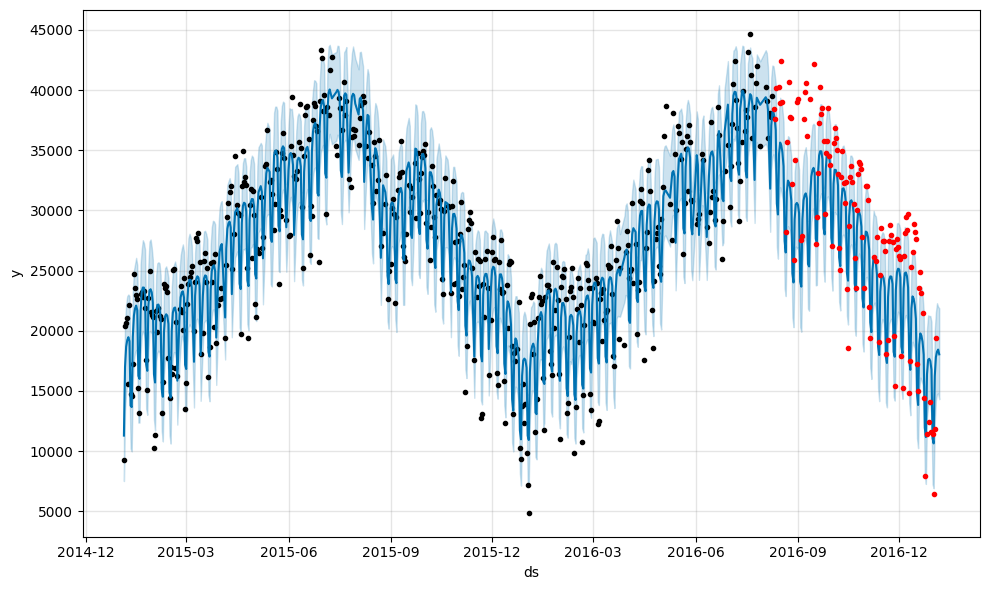

In [71]:
fig1 = modelo_sem_outliers.plot(previsao)

plt.plot(df_teste['ds'], df_teste['y'], '.r');

In [72]:
df_previsao = previsao[['ds', 'yhat']]
df_comparacao = pd.merge(df_previsao, df_teste, on='ds')
df_comparacao

,ds,yhat,y
0,2016-08-10,38131.605713,38430
1,2016-08-11,37716.520981,37626
2,2016-08-12,36671.560981,40159
3,2016-08-15,34697.765458,40236
4,2016-08-16,35637.262251,38911
...,...,...,...
120,2016-12-30,16759.096677,11566
121,2016-12-31,11051.420270,11424
122,2017-01-01,10635.029814,6421
123,2017-01-02,16235.675964,11823


In [73]:
mse = mean_squared_error(df_comparacao['y'], df_comparacao['yhat'])
rmse = np.sqrt(mse)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')

MSE: 15708852.007508356
RMSE: 3963.4394164044384


In [74]:
np.random.seed(4587)

modelo_sem_outliers = Prophet(yearly_seasonality=True)

modelo_sem_outliers.fit(df_treino)
futuro = modelo_sem_outliers.make_future_dataframe(periods=365, freq='D')
previsao = modelo_sem_outliers.predict(futuro)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


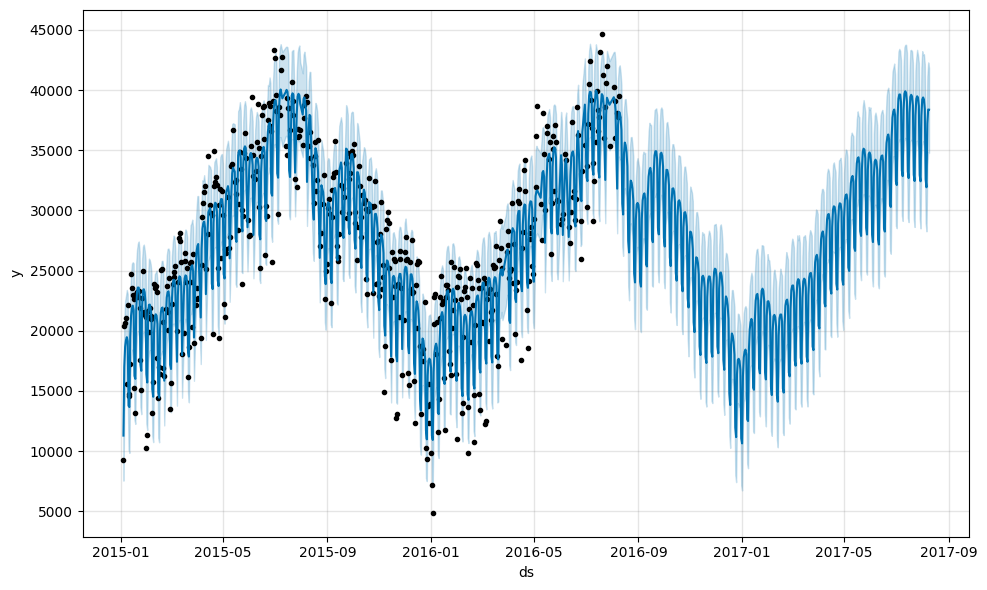

In [75]:
fig = plot(modelo_sem_outliers, previsao)
fig.show()